# 03 · Modelado — HU-05 / HU-06 / HU-07

Escalera: **Regresión logística → Árbol → Random Forest → GBM** (LightGBM si está instalado; ver
nota más abajo). Reglas de validez (plan, errores 4 y 5):

- Toda la comparación y el tuning se hacen con **CV estratificada (5 folds) solo sobre train**.
  El conjunto de test **no se toca** en este notebook.
- Mismo CV y mismas métricas para todos: **ROC-AUC, PR-AUC** (independientes del umbral) y
  **Recall / Precision / F1** en el umbral que maximiza F1 sobre las predicciones *out-of-fold*.
- Imputación y encoding viven dentro del `Pipeline`, así que se re-ajustan en cada fold.

In [1]:
import json
import time

import numpy as np
import pandas as pd

from src.data import load_dataset, split_train_test
from src.evaluation import compute_metrics
from src.features import engineer
from src.models import CV, GBM_BACKEND, best_f1_threshold, cv_evaluate, get_models, tune_gbm

pd.set_option("display.width", 140)
X, y = load_dataset()
X = engineer(X)
X_train, X_test, y_train, y_test = split_train_test(X, y)
del X_test, y_test  # el test no se usa en este notebook
print("train:", X_train.shape, f"| positivos {y_train.mean():.2%}")
print("Backend del modelo de boosting:", GBM_BACKEND)

train: (55978, 43) | positivos 8.97%
Backend del modelo de boosting: sklearn-hist-gradient-boosting

> **Nota sobre el entorno.** Si `lightgbm` no está instalado, `src/models.py` usa
> `HistGradientBoostingClassifier` de scikit-learn (mismo algoritmo base: boosting de árboles con
> histogramas, `class_weight="balanced"`). Con `uv sync` en un entorno con acceso a PyPI se usa
> LightGBM automáticamente y este notebook no cambia. El backend usado queda impreso arriba y
> guardado en `artifacts/winner.json`.

## 1. Los tres modelos base + GBM con hiperparámetros por defecto

In [2]:
models = get_models()
results, oof_store = [], {}


def evaluate(name, model):
    t = time.time()
    folds, oof = cv_evaluate(model, X_train, y_train, CV)
    thr = best_f1_threshold(y_train, oof)
    m = compute_metrics(y_train, oof, thr)
    results.append(
        {
            "modelo": name,
            "roc_auc": folds["roc_auc"].mean(),
            "roc_auc_std": folds["roc_auc"].std(),
            "pr_auc": folds["pr_auc"].mean(),
            "pr_auc_std": folds["pr_auc"].std(),
            "recall": m["recall"],
            "precision": m["precision"],
            "f1": m["f1"],
            "umbral": thr,
            "seg": round(time.time() - t),
        }
    )
    oof_store[name] = oof
    print(f"{name:<14} ROC-AUC {folds['roc_auc'].mean():.4f}  PR-AUC {folds['pr_auc'].mean():.4f}"
          f"  Recall {m['recall']:.3f}  F1 {m['f1']:.3f}  (umbral {thr:.2f}, {results[-1]['seg']} s)")


for name in ["LogReg", "Árbol", "RandomForest", "GBM"]:
    evaluate(name if name != "GBM" else "GBM (defecto)", models[name])

LogReg         ROC-AUC 0.6484  PR-AUC 0.1646  Recall 0.348  F1 0.228  (umbral 0.58, 12 s)
Árbol          ROC-AUC 0.6216  PR-AUC 0.1490  Recall 0.361  F1 0.209  (umbral 0.56, 6 s)
RandomForest   ROC-AUC 0.6510  PR-AUC 0.1652  Recall 0.460  F1 0.227  (umbral 0.51, 41 s)
GBM (defecto)  ROC-AUC 0.6473  PR-AUC 0.1689  Recall 0.304  F1 0.225  (umbral 0.58, 13 s)

## 2. Ajuste del GBM (HU-06): `RandomizedSearchCV`, 15 iteraciones, solo sobre train
Se hace al final de la escalera, como indica el plan. Criterio: ROC-AUC (CV de 3 folds para
acotar el tiempo); luego el modelo ajustado se re-evalúa con **el mismo CV de 5 folds** que los demás.

In [3]:
t0 = time.time()
search = tune_gbm(X_train, y_train, n_iter=15, cv_splits=3)
print(f"Búsqueda terminada en {time.time() - t0:.0f} s")
cvr = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
cols = ["mean_test_score", "std_test_score"] + [c for c in cvr.columns if c.startswith("param_")]
print(cvr[cols].head(5).round(4).to_string(index=False))
print("\nMejores hiperparámetros:", search.best_params_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Búsqueda terminada en 149 s
 mean_test_score  std_test_score  param_model__min_samples_leaf  param_model__max_leaf_nodes  param_model__max_iter  param_model__max_features  param_model__learning_rate  param_model__l2_regularization
          0.6524          0.0030                             20                           31                    100                        0.5                        0.10                              10
          0.6520          0.0040                             20                           15                    500                        1.0                        0.05                              10
          0.6513          0.0027                             20                           31                    500                        0.7                        0.02                              10
          0.6512          0.0048                            100                           15       

In [4]:
tuned = models["GBM"].set_params(**search.best_params_)
evaluate("GBM (ajustado)", tuned)

GBM (ajustado) ROC-AUC 0.6532  PR-AUC 0.1707  Recall 0.371  F1 0.230  (umbral 0.56, 15 s)

## 3. Tabla comparativa y elección del ganador (HU-07)
El ganador es el de mayor **ROC-AUC medio en CV** (criterio fijado antes de ver resultados);
PR-AUC se reporta como segunda métrica porque la clase positiva es solo ~9 %.

In [5]:
res = pd.DataFrame(results)
res["ganador"] = ""
res.loc[res["roc_auc"].idxmax(), "ganador"] = "◄"
print(res.round(4).to_string(index=False))
res

        modelo  roc_auc  roc_auc_std  pr_auc  pr_auc_std  recall  precision     f1  umbral  seg ganador
        LogReg   0.6484       0.0069  0.1646      0.0039  0.3485     0.1698 0.2283    0.58   12        
         Árbol   0.6216       0.0059  0.1490      0.0049  0.3610     0.1467 0.2086    0.56    6        
  RandomForest   0.6510       0.0054  0.1652      0.0034  0.4596     0.1509 0.2272    0.51   41        
 GBM (defecto)   0.6473       0.0036  0.1689      0.0038  0.3045     0.1782 0.2249    0.58   13        
GBM (ajustado)   0.6532       0.0065  0.1707      0.0031  0.3714     0.1671 0.2304    0.56   15       ◄

,modelo,roc_auc,roc_auc_std,pr_auc,pr_auc_std,recall,precision,f1,umbral,seg,ganador
0,LogReg,0.648388,0.006892,0.164569,0.003947,0.348467,0.169804,0.228340,0.58,12,
1,Árbol,0.621566,0.005863,0.149029,0.004869,0.361012,0.146671,0.208595,0.56,6,
2,RandomForest,0.650971,0.005381,0.165161,0.003353,0.459578,0.150869,0.227165,0.51,41,
3,GBM (defecto),0.647346,0.003623,0.168941,0.003817,0.304460,0.178247,0.224853,0.58,13,
4,GBM (ajustado),0.653177,0.006504,0.170701,0.003075,0.371366,0.167055,0.230446,0.56,15,◄


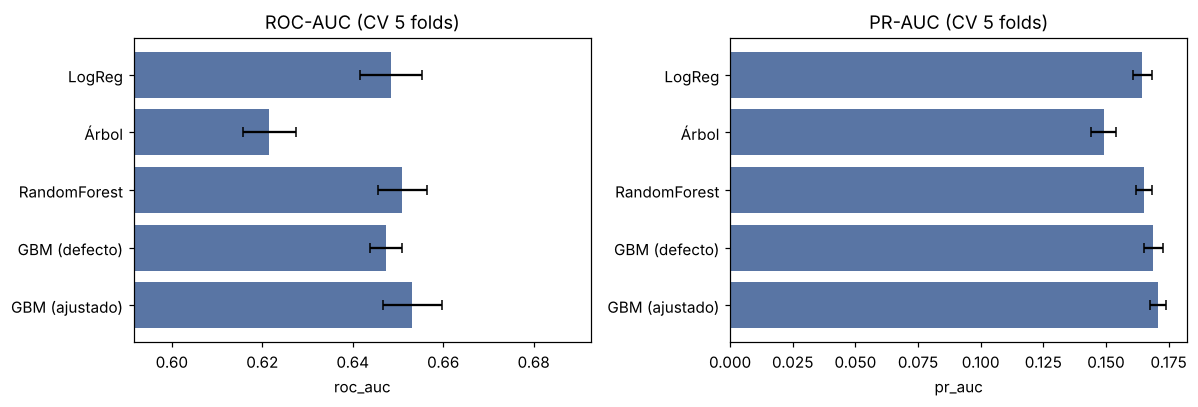

In [6]:
import matplotlib.pyplot as plt  # noqa: E402
import seaborn as sns  # noqa: E402

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, (col, err, title) in zip(ax, [("roc_auc", "roc_auc_std", "ROC-AUC (CV 5 folds)"),
                                      ("pr_auc", "pr_auc_std", "PR-AUC (CV 5 folds)")]):
    sns.barplot(data=res, y="modelo", x=col, ax=a, color="#4c72b0")
    a.errorbar(res[col], range(len(res)), xerr=res[err], fmt="none", c="k", capsize=3)
    a.set_title(title)
    a.set_xlim(res[col].min() - 0.03 if col == "roc_auc" else 0, None)
    a.set_ylabel("")
fig.tight_layout()
fig.savefig("../reports/figures/comparacion_modelos_cv.png", dpi=130)

## 4. Guardar resultados para el notebook 04

In [7]:
win = res.loc[res["roc_auc"].idxmax()]
print("Ganador:", win["modelo"], f"| ROC-AUC {win['roc_auc']:.4f} | umbral {win['umbral']:.2f}")

res.drop(columns="ganador").to_csv("../artifacts/cv_results.csv", index=False)
winner = {
    "modelo": win["modelo"],
    "umbral": float(win["umbral"]),
    "gbm_backend": GBM_BACKEND,
    "gbm_best_params": {k: (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()},
}
with open("../artifacts/winner.json", "w", encoding="utf-8") as f:
    json.dump(winner, f, indent=2, ensure_ascii=False)
winner

Ganador: GBM (ajustado) | ROC-AUC 0.6532 | umbral 0.56

{'modelo': 'GBM (ajustado)', 'umbral': 0.5599999999999999, 'gbm_backend': 'sklearn-hist-gradient-boosting', 'gbm_best_params': {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 31, 'model__max_iter': 100, 'model__max_features': 0.5, 'model__learning_rate': 0.1, 'model__l2_regularization': 10}}

## Conclusiones
- **Ganador por criterio previo:** GBM ajustado (ROC-AUC CV ≈ 0.653, PR-AUC ≈ 0.171).
- **Pero la diferencia es pequeña:** GBM ajustado, Random Forest (0.651) y regresión logística
  (0.648) quedan dentro de ~1 desviación estándar entre folds (≈ 0.005-0.007), es decir, **no se
  distinguen estadísticamente**. El árbol simple es claramente peor (0.622).
- El rendimiento "modesto" (ROC-AUC ≈ 0.62-0.68) es lo esperado en este dataset: la información
  disponible al alta explica solo parte del reingreso. El valor del proyecto está en la
  metodología (sin fuga, test intacto) y en la interpretación (notebook 04).